In [1]:
import snapatac2 as snap
import glob, os
from pathlib import Path
from typing import List, Tuple
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import pandas as pd
import anndata as ad
import sys
from plotly.subplots import make_subplots

In [2]:
sys.path.append(os.path.abspath('/home/huc/projects/scAuto/scAnnotation'))
sys.path.append(os.path.abspath('/home/huc/projects/scRNA_resources/markers'))

import scAnnotation_helpers as scAnnotation_helpers
import marker_helpers as marker_helpers

import importlib
importlib.reload(scAnnotation_helpers)
importlib.reload(marker_helpers)

marker_yaml_file = "/home/huc/projects/scRNA_resources/markers/marker_collections/mouse_bone_marrow.yaml"

2025-05-31 11:41:09 - INFO - cffi mode is CFFI_MODE.ANY
/home/huc/.conda/envs/py312r43/lib/python3.12/site-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2025-05-31 11:41:09 - INFO - R home found: /home/huc/.conda/envs/py312r43/lib/R
/home/huc/.conda/envs/py312r43/lib/python3.12/site-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2025-05-31 11:41:09 - INFO - R library path: /cm/shared/apps/slurm/current/lib64/slurm:/cm/shared/apps/slurm/current/lib64
2025-05-31 11:41:09 - INFO - LD_LIBRARY_PATH: /cm/shared/ap

## Read data

In [ ]:
data = snap.read_dataset("/home/huc/projects/Ruoqiong_Cao.IAHSC/scATAC/2.QC/IAHSC_atac.h5ads") # a copy of IAHSC_atac.h5ads.bak_batch_corrected

In [9]:
data

AnnDataSet object with n_obs x n_vars = 115448 x 5267565 backed at '/home/huc/projects/Ruoqiong_Cao.IAHSC/scATAC/2.QC/IAHSC_atac.h5ads'
contains 16 AnnData objects with keys: 'WT_infected_rep1', 'WT_infected_rep2', 'WT_infected_rep3', 'WT_infected_rep4', 'WT_naive_rep1', 'WT_naive_rep2', 'WT_naive_rep3', 'WT_naive_rep4', 'new_DNMT3A_KO_infected_rep1', 'new_DNMT3A_KO_infected_rep2', 'new_DNMT3A_KO_infected_rep3', 'new_DNMT3A_KO_infected_rep4', 'new_DNMT3A_KO_naive_rep1', 'new_DNMT3A_KO_naive_rep2', 'new_DNMT3A_KO_naive_rep3', 'new_DNMT3A_KO_naive_rep4'
    obs: 'sample', 'leiden'
    var: 'count', 'selected'
    uns: 'AnnDataSet', 'reference_sequences', 'spectral_eigenvalue'
    obsm: 'X_spectral_harmony', 'X_umap', 'X_spectral_mnn', 'X_spectral'
    obsp: 'distances'

# Re-compute UMAP for data

In [10]:
snap.tl.umap(data)
snap.pp.knn(data, n_neighbors=30)
for res in [0.1, 0.2, 0.3, 0.4, 0.5, 0.8, 1]:
    snap.tl.leiden(
        data, key_added=f"leiden_res_{res:4.2f}", resolution=res
    )

In [11]:
snap.tl.umap(data, min_dist = 0.8, spread = 0.8)

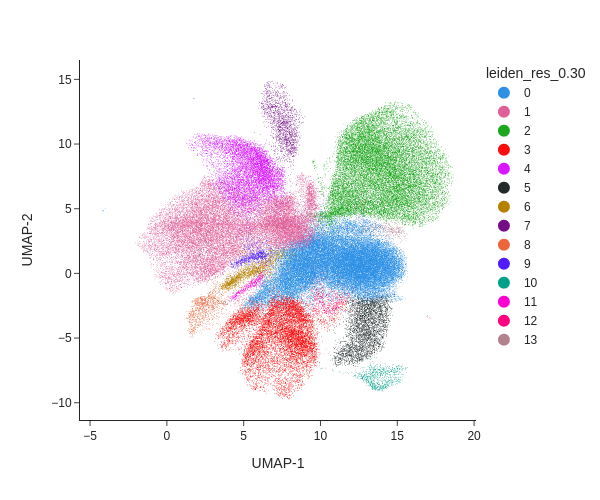

In [12]:
snap.pl.umap(data, color='leiden_res_0.30', interactive=False, height=500)


In [32]:
data

AnnDataSet object with n_obs x n_vars = 115448 x 5267565 backed at '/home/huc/projects/Ruoqiong_Cao.IAHSC/scATAC/2.QC/IAHSC_atac.h5ads'
contains 16 AnnData objects with keys: 'WT_infected_rep1', 'WT_infected_rep2', 'WT_infected_rep3', 'WT_infected_rep4', 'WT_naive_rep1', 'WT_naive_rep2', 'WT_naive_rep3', 'WT_naive_rep4', 'new_DNMT3A_KO_infected_rep1', 'new_DNMT3A_KO_infected_rep2', 'new_DNMT3A_KO_infected_rep3', 'new_DNMT3A_KO_infected_rep4', 'new_DNMT3A_KO_naive_rep1', 'new_DNMT3A_KO_naive_rep2', 'new_DNMT3A_KO_naive_rep3', 'new_DNMT3A_KO_naive_rep4'
    obs: 'sample', 'leiden', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00'
    var: 'count', 'selected'
    uns: 'spectral_eigenvalue', 'reference_sequences', 'AnnDataSet'
    obsm: 'X_spectral_harmony', 'X_spectral_mnn', 'X_umap', 'X_spectral'
    obsp: 'distances'

In [28]:
data.close()

## Annotation using gene activity (without gene expression imputation)

In [ ]:
data = snap.read_dataset("/home/huc/projects/Ruoqiong_Cao.IAHSC/scATAC/2.QC/IAHSC_atac.h5ads") # a copy of IAHSC_atac.h5ads.bak_batch_corrected

In [13]:
%%time
gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.mm10)
sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)
gene_matrix

CPU times: user 12min 54s, sys: 32.9 s, total: 13min 27s
Wall time: 2min 5s


AnnData object with n_obs × n_vars = 115448 × 53241
    obs: 'sample', 'leiden', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00'
    var: 'n_cells'
    uns: 'log1p'

In [14]:
# Copy over UMAP embedding
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]

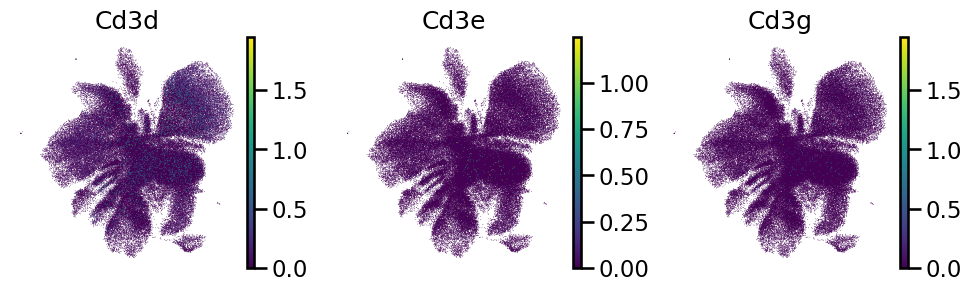

In [18]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "T")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=specific_markers,
        use_raw = False,
        legend_loc="on data", frameon=False, ncols=5,
    )

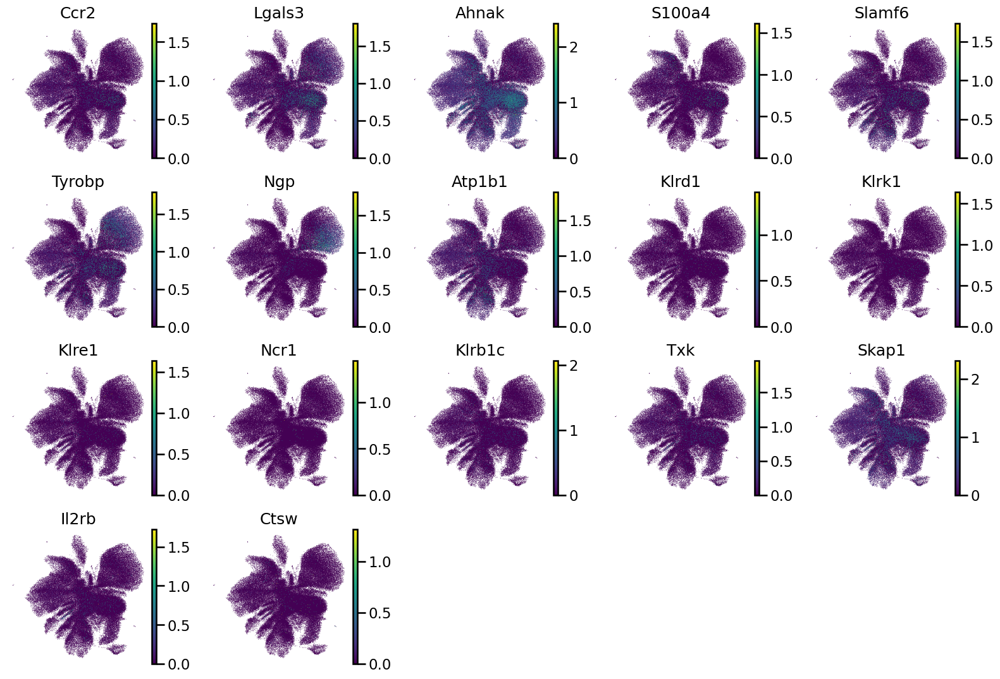

In [19]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Natural_killer")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

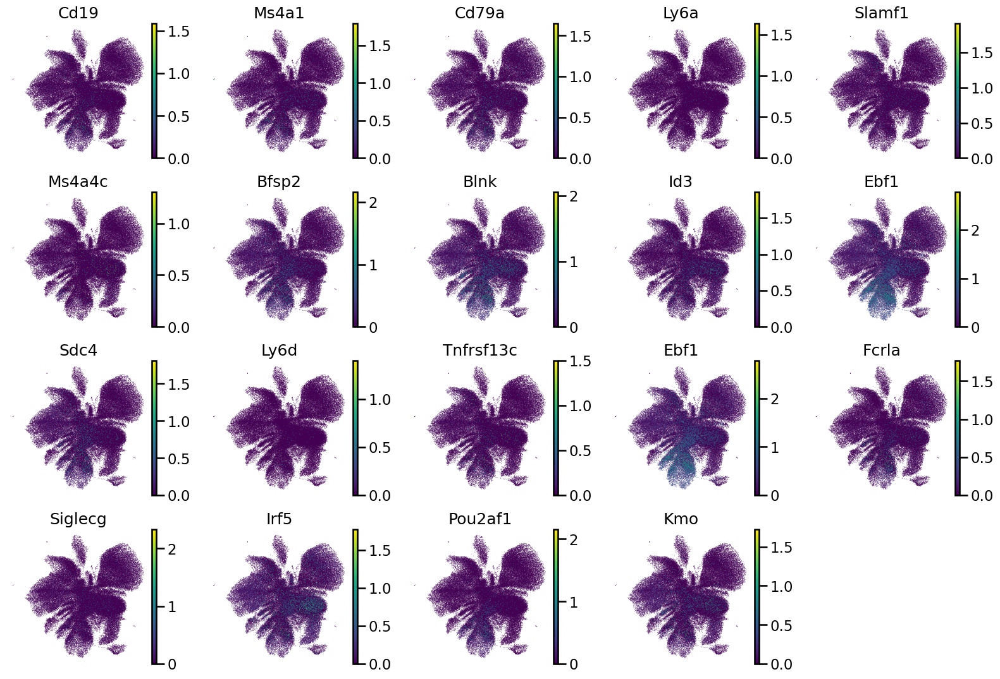

In [20]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "B")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

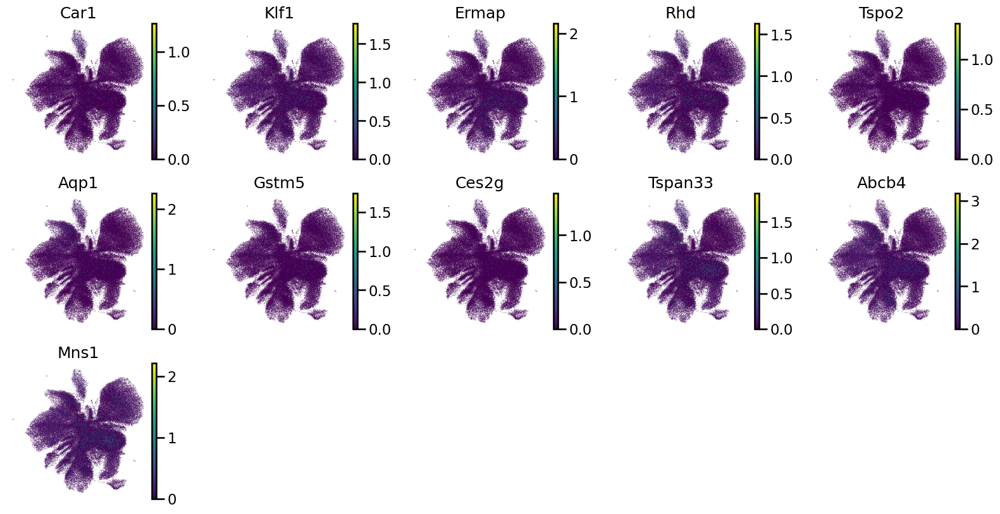

In [21]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Erythrocyte")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

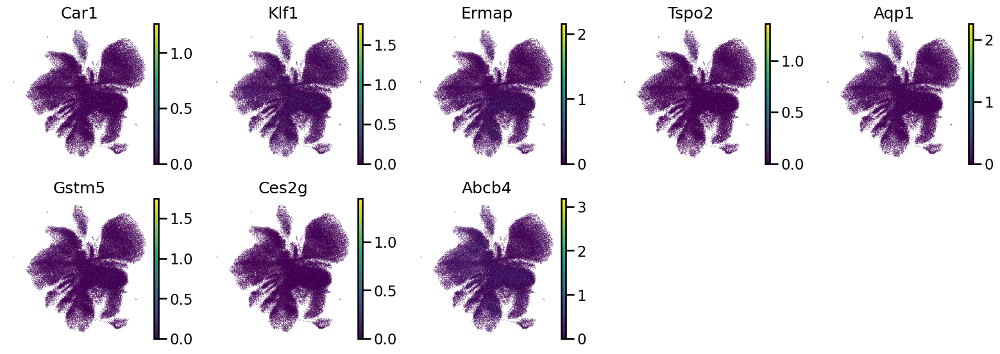

In [22]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MkE")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

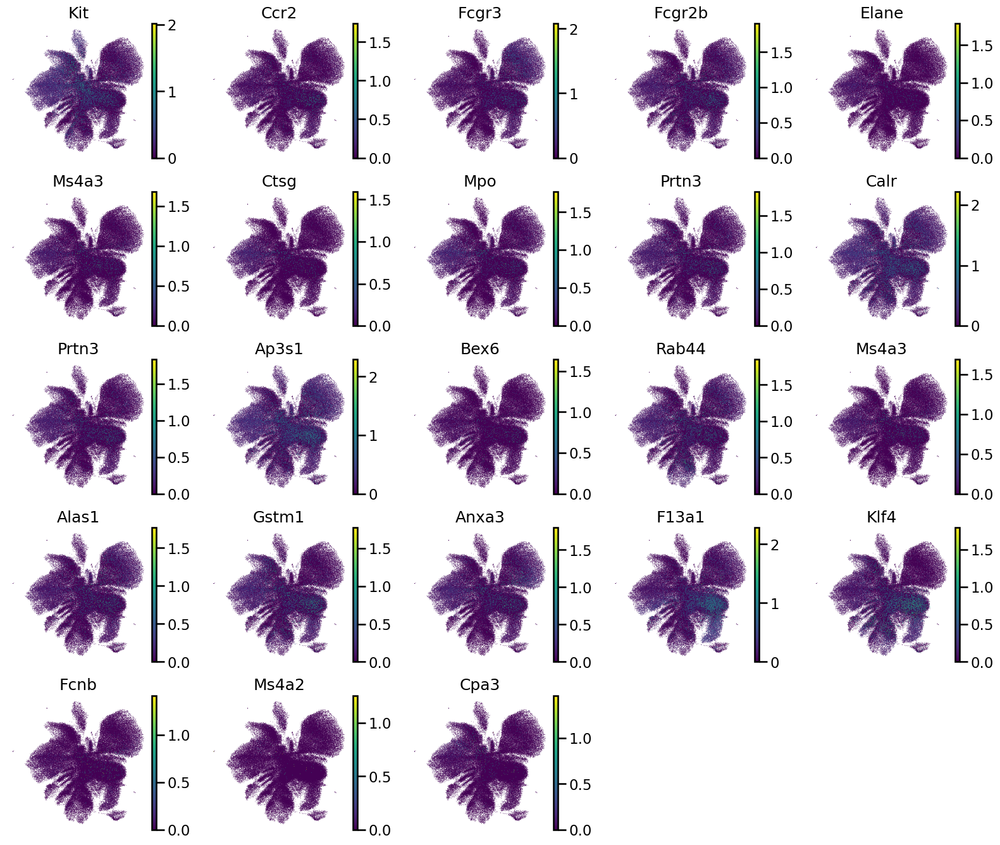

In [23]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "GMP")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

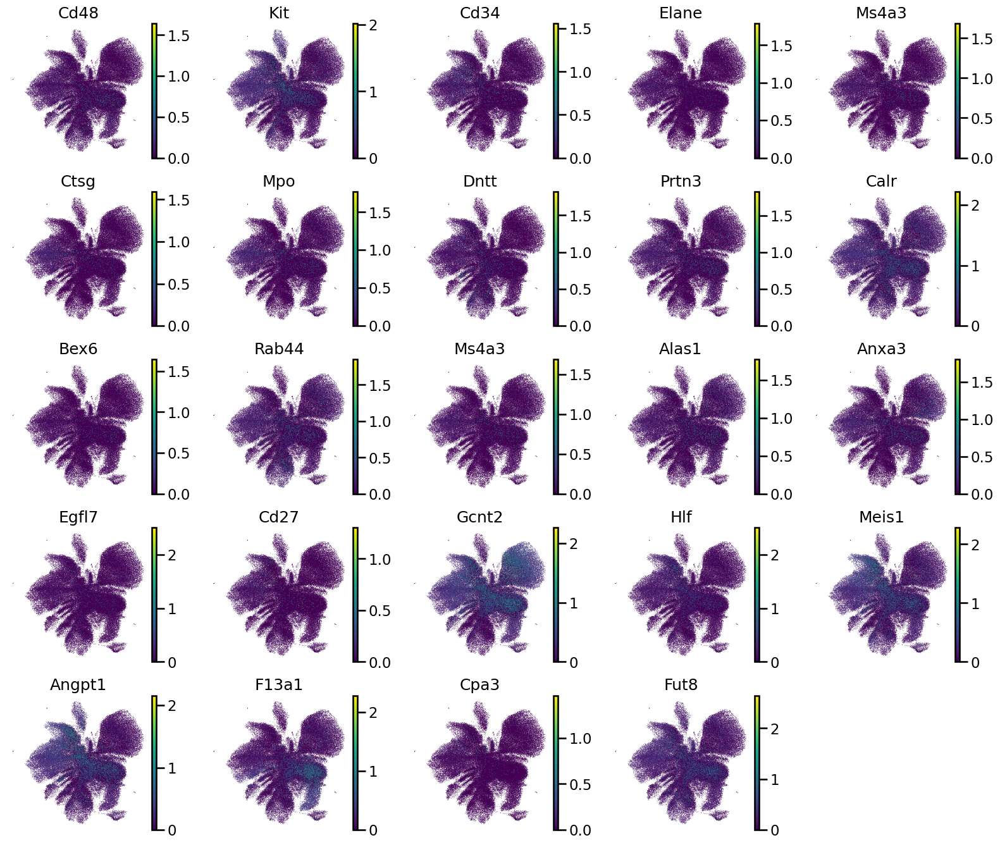

In [24]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MMP3")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

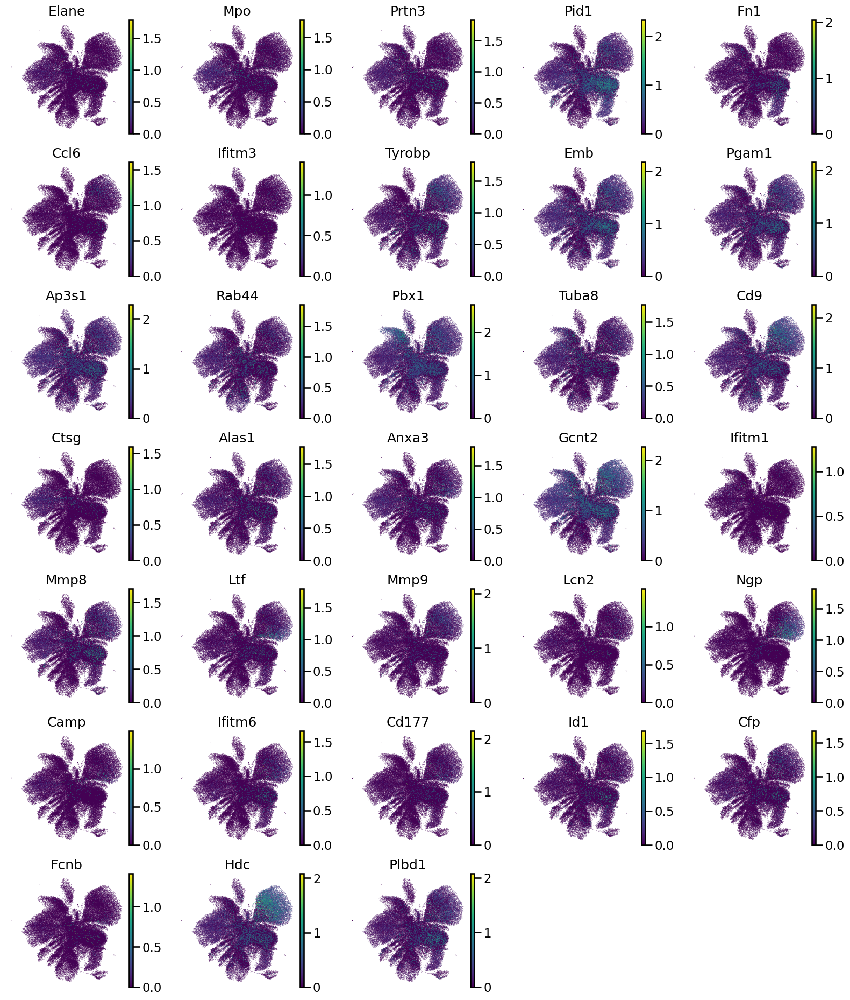

In [25]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Neutrophil")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

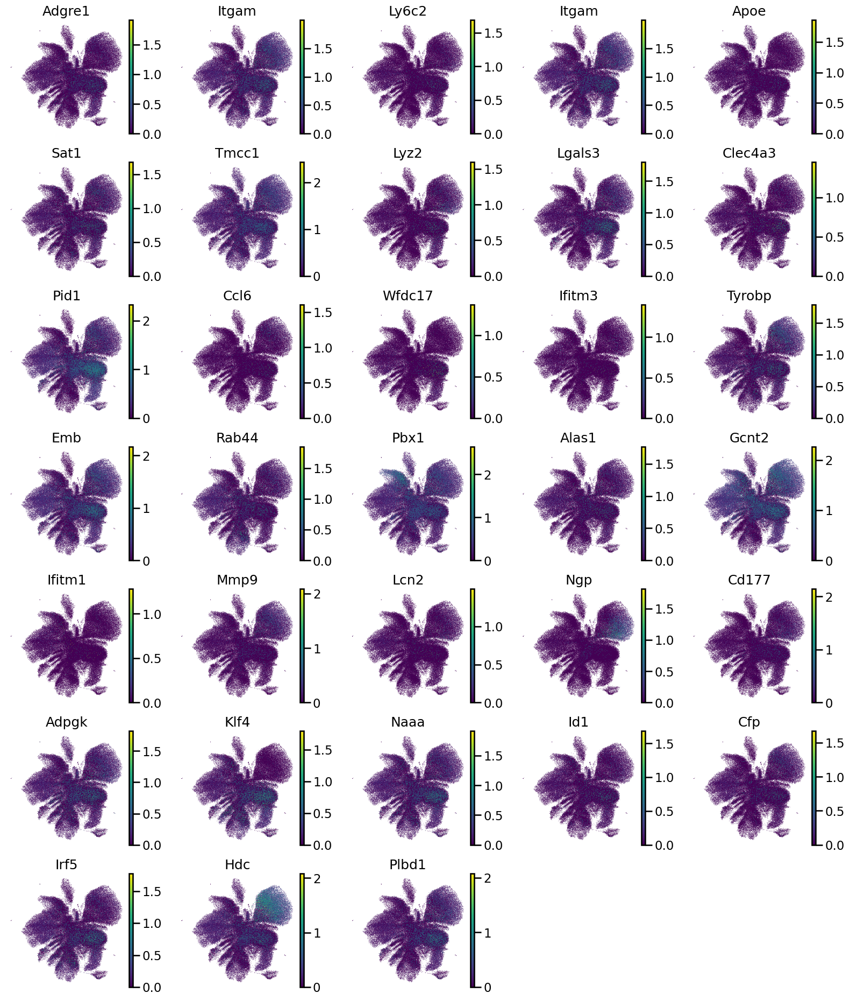

In [26]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Macrophage")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

In [27]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MkP")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

KeyError: 'Could not find key H1fx in .var_names or .obs.columns.'

<Figure size 1905x900 with 0 Axes>

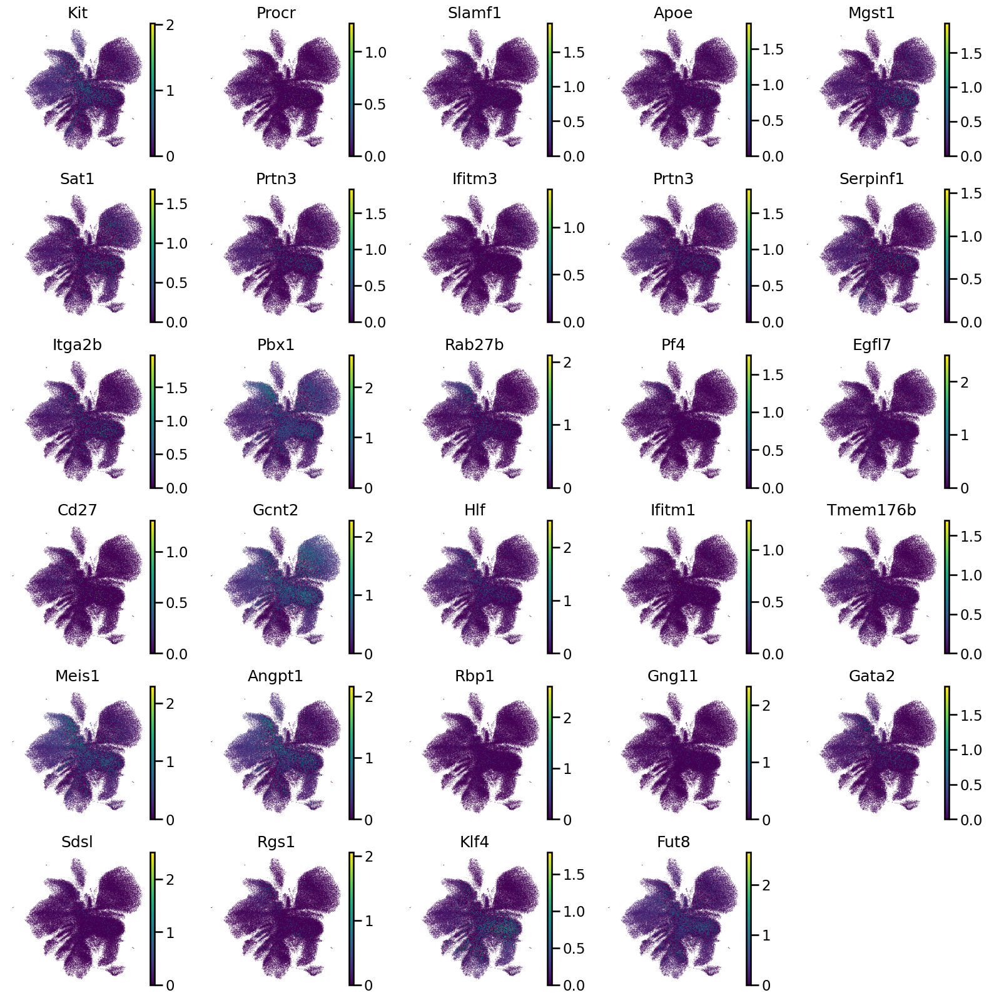

In [29]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

In [ ]:
gene_matrix.write("IAHSC_gene_mat.no_imputation.h5ad", compression='gzip')

In [ ]:
data.close()

# Perform imputation

In [41]:
data = snap.read_dataset("/home/huc/projects/Ruoqiong_Cao.IAHSC/scATAC/2.QC/IAHSC_atac.h5ads") # a copy of IAHSC_atac.h5ads.bak_batch_corrected

In [35]:
%%time
gene_matrix = snap.pp.make_gene_matrix(data, snap.genome.mm10)
sc.pp.filter_genes(gene_matrix, min_cells= 5)
sc.pp.normalize_total(gene_matrix)
sc.pp.log1p(gene_matrix)
gene_matrix

CPU times: user 12min 2s, sys: 21.5 s, total: 12min 24s
Wall time: 1min 9s


AnnData object with n_obs × n_vars = 115448 × 53241
    obs: 'sample', 'leiden', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00'
    var: 'n_cells'
    uns: 'log1p'

In [37]:
# %%time
sc.external.pp.magic(gene_matrix, solver="approximate")

In [38]:
gene_matrix.write("IAHSC_gene_mat.imputated.h5ad", compression='gzip')

... storing 'sample' as categorical


## Explore the imputed expression

In [42]:
# Copy over UMAP embedding
gene_matrix.obsm["X_umap"] = data.obsm["X_umap"]

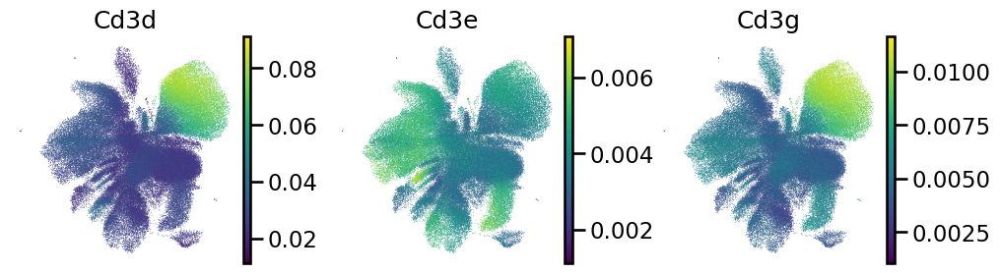

In [43]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "T")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=specific_markers,
        use_raw = False,
        legend_loc="on data", frameon=False, ncols=5,
    )

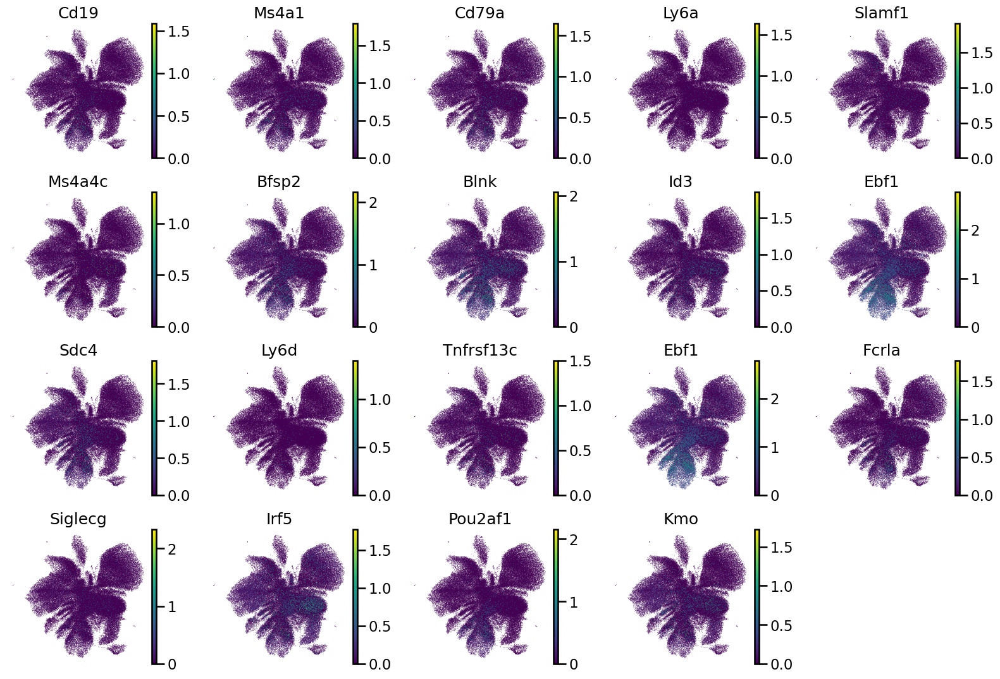

In [44]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "B")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

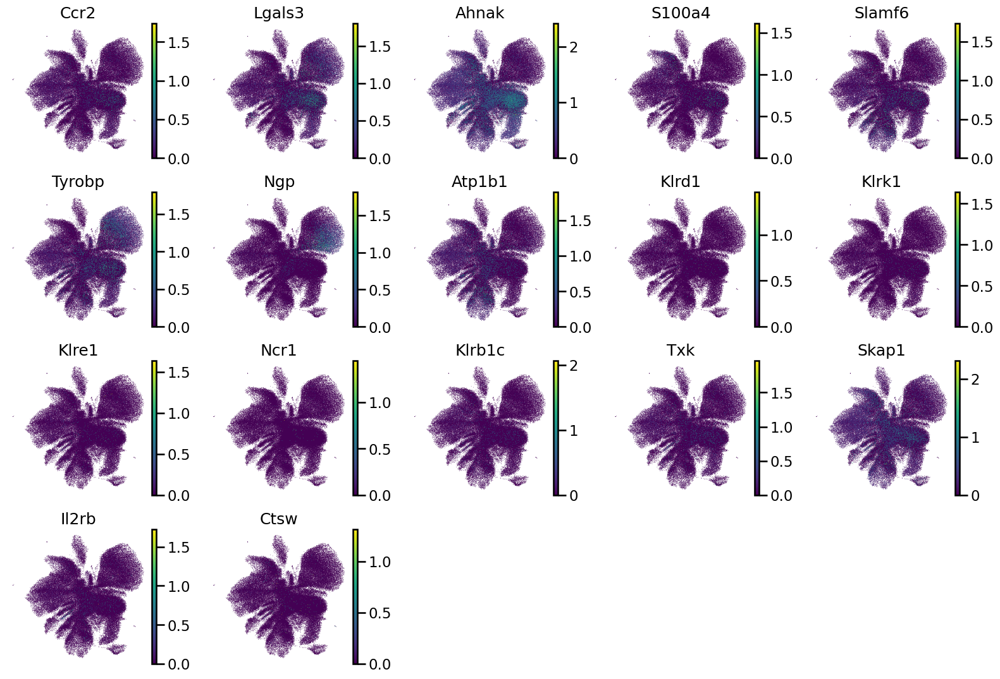

In [45]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Natural_killer")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

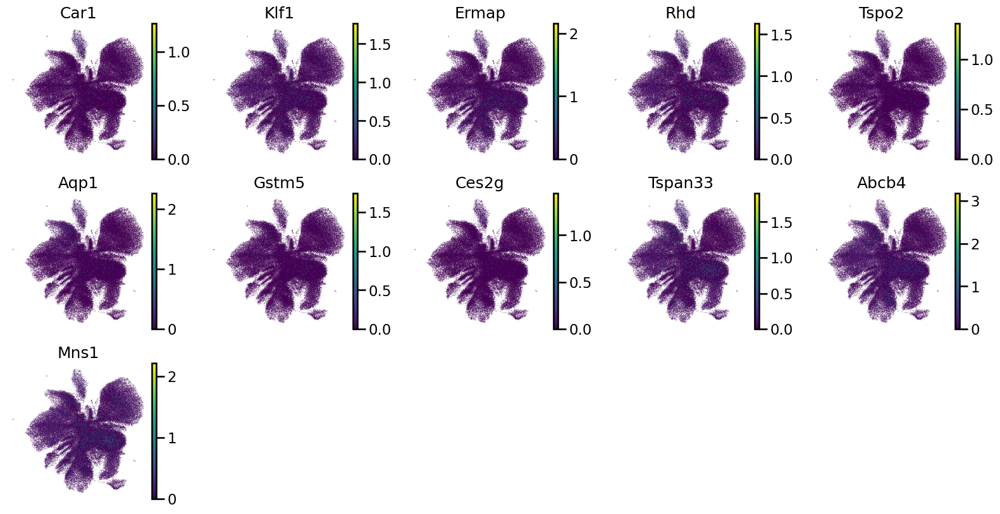

In [46]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Erythrocyte")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

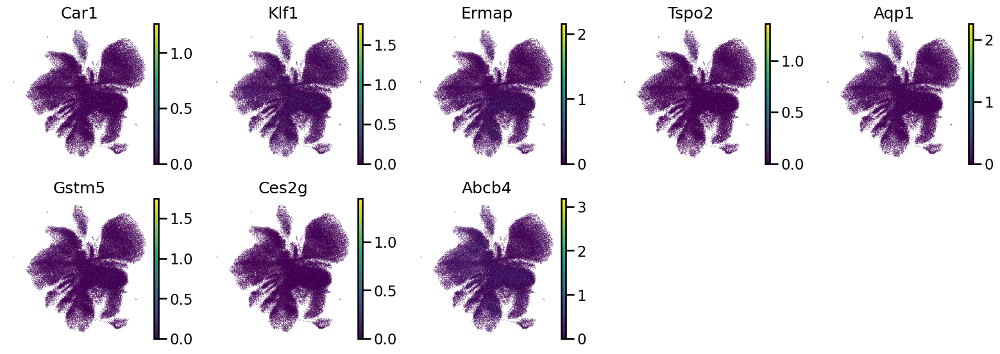

In [47]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MkE")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

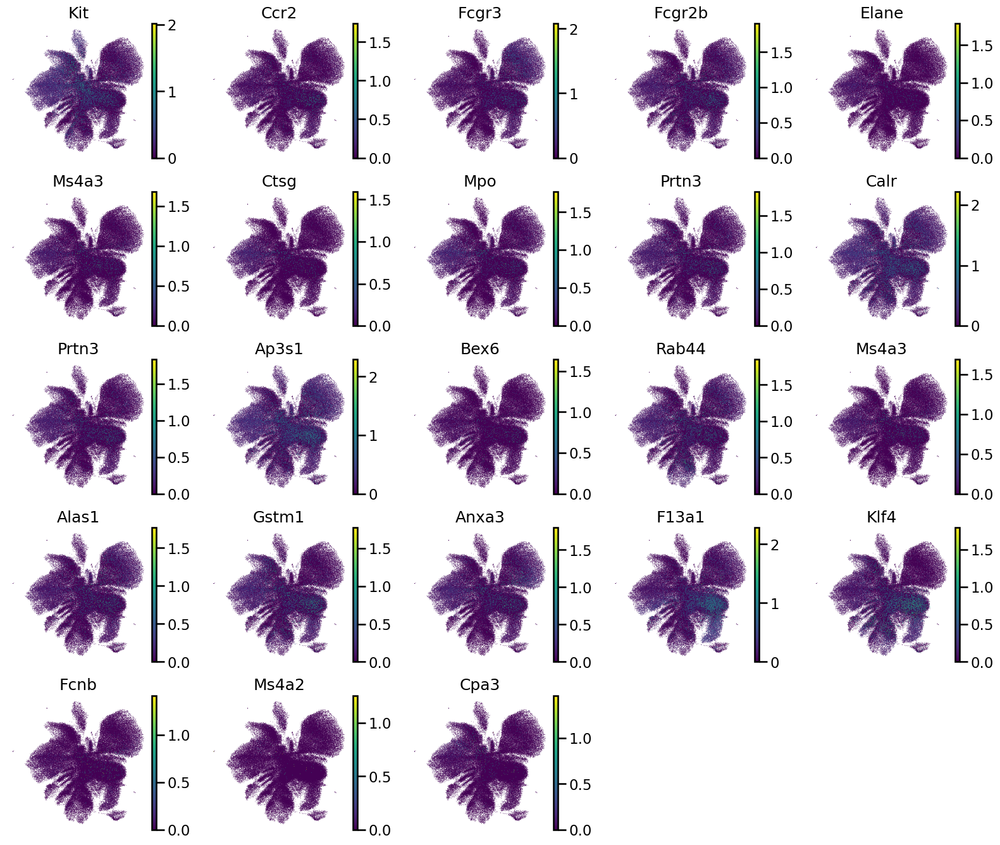

In [48]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "GMP")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

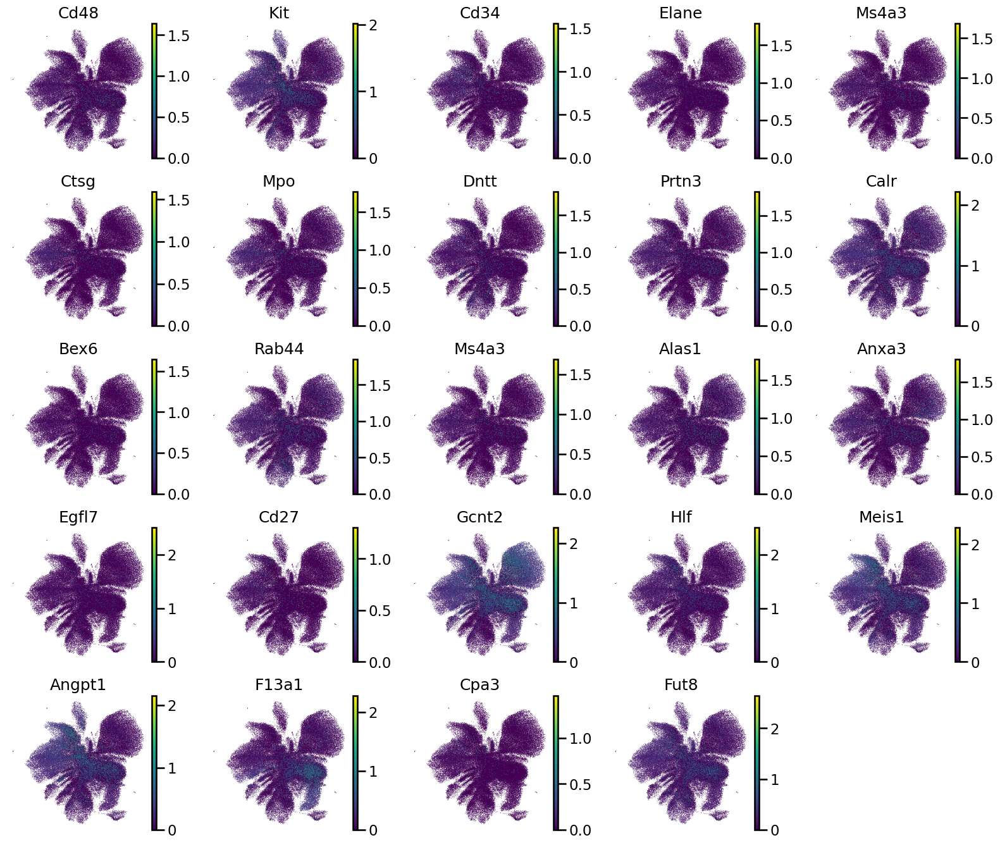

In [49]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MMP3")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

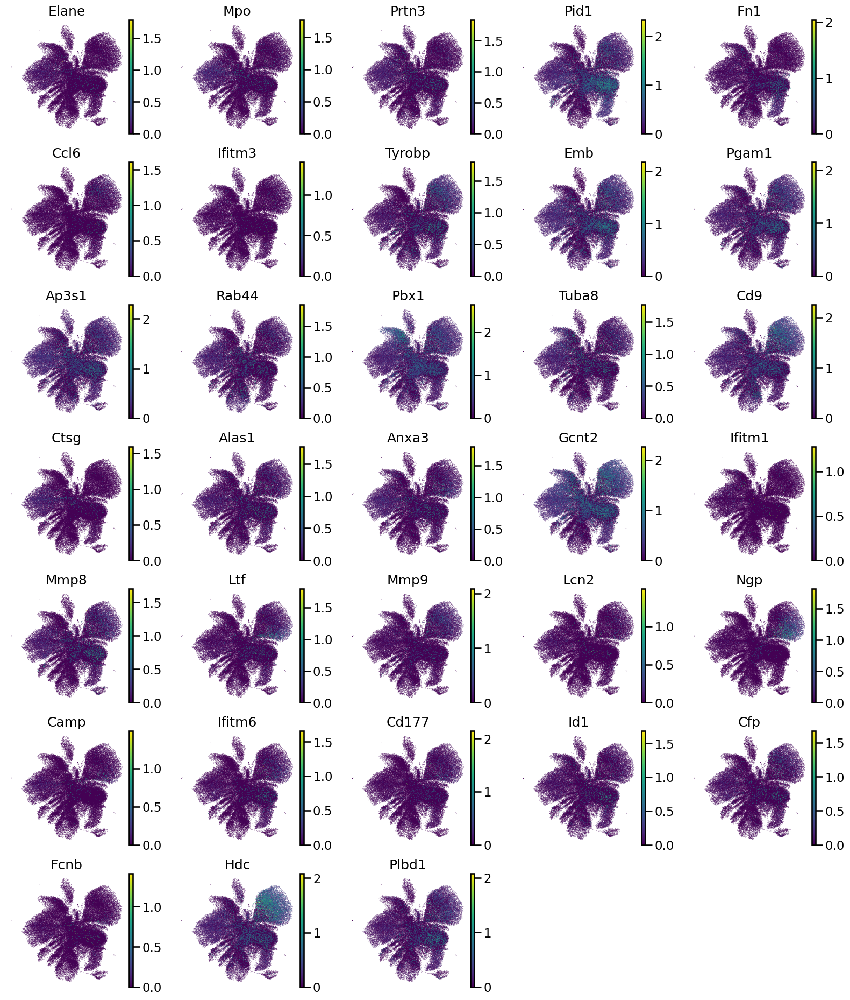

In [50]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Neutrophil")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

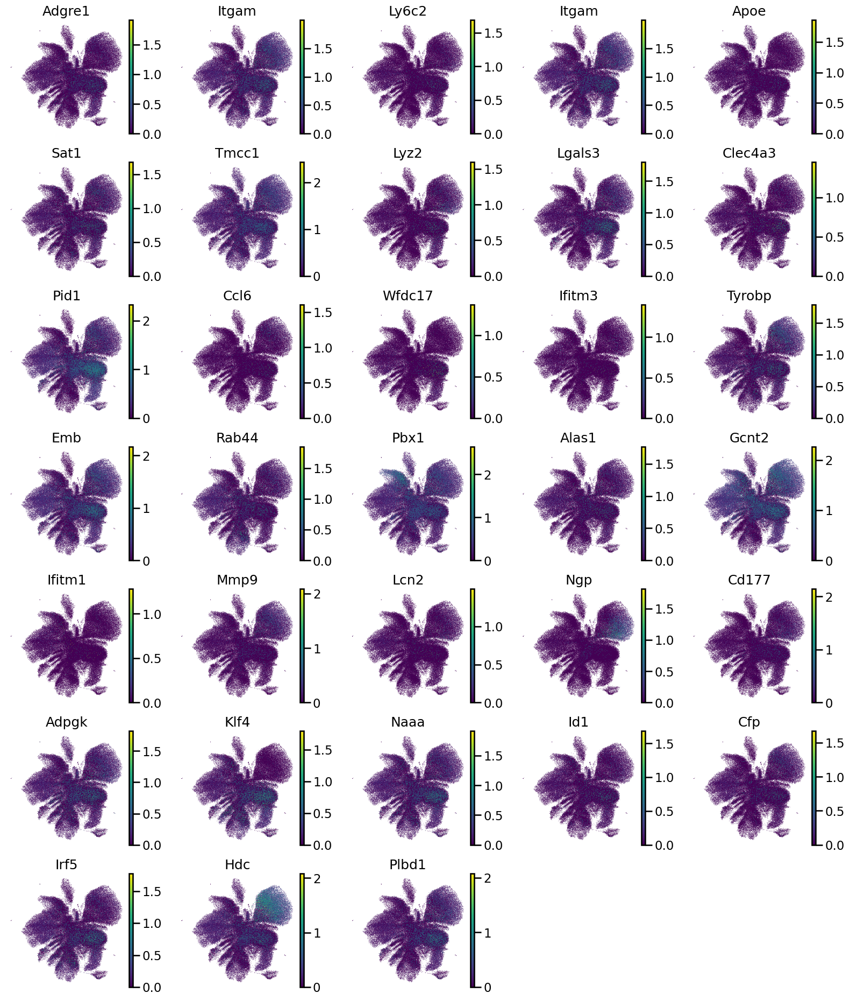

In [51]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Macrophage")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

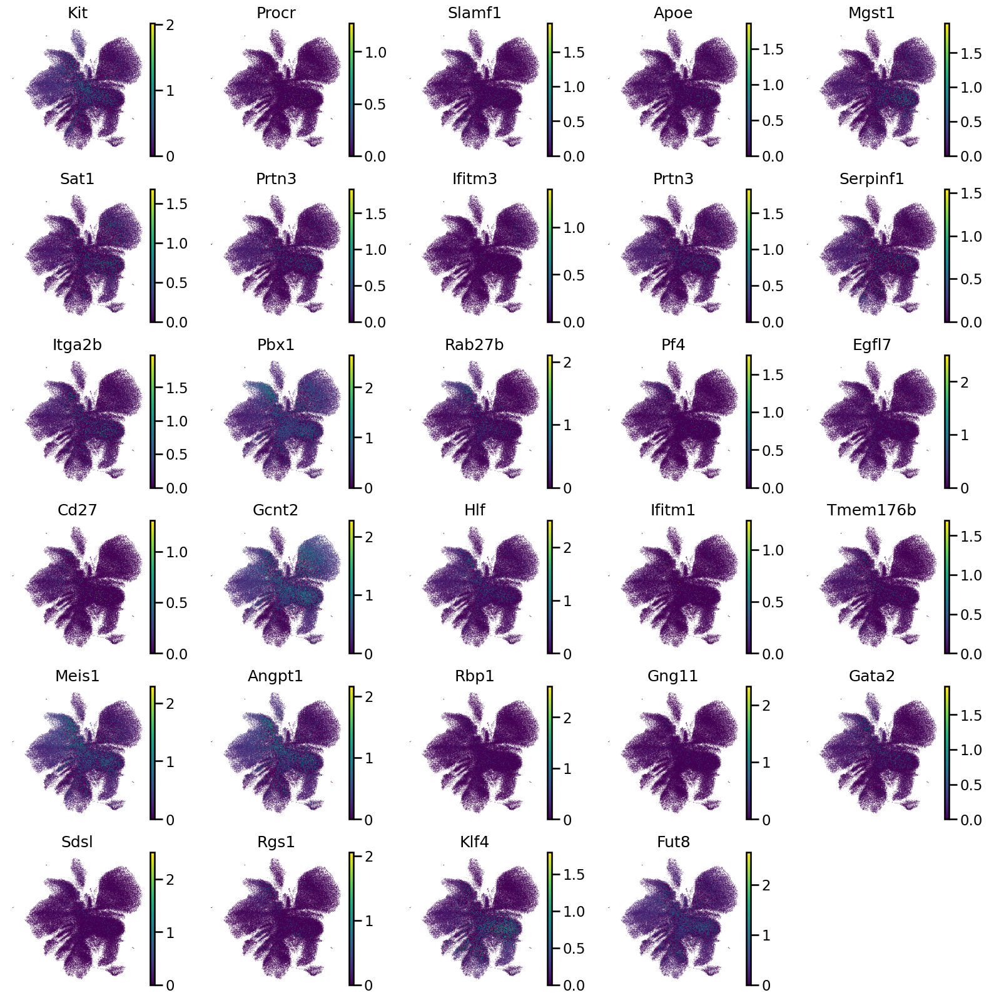

In [52]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        gene_matrix,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

# Integration of scRNA and scATAC
### Several things has to be addressed
* Both scRNA and scATC should be raw counts
* The raw counts of scRNA is stored in in unintegrated adata
* scRNA vars should be gene symbols

In [10]:
scRNA = sc.read_h5ad("/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.annotation_general.April23.h5ad")

In [18]:
scRNA

AnnData object with n_obs × n_vars = 158292 × 2854
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'S_score', 'G2M_score', 'phase', 'ed_logprob', 'ed_fdr', 'ed_class', 'doublet_score', 'predicted_doublet', 'leiden', 'sample', 'leiden_uncorrected', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00', 'cell_type_general'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cell_type_general_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.50_colors', 'leiden_res_

In [ ]:
gene_matrix = snap.read("IAHSC_gene_mat.no_imputation.h5ad", backed = None)

In [16]:
gene_matrix


AnnData object with n_obs × n_vars = 115448 × 53241
    obs: 'sample', 'leiden', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00', 'cell_type_general'
    var: 'n_cells'
    uns: 'log1p'
    obsm: 'X_umap'

In [5]:
gene_matrix.obs['cell_type_general'] = pd.NA
joint = ad.concat(
    [scRNA, gene_matrix],
    join='inner',
    label='modality',
    keys=["scRNA", "scATAC"],
    index_unique='_',
)

In [8]:
sc.pp.filter_genes(joint, min_cells=5)
sc.pp.highly_variable_genes(
    joint,
    n_top_genes = 5000,
    flavor="seurat_v3",
    batch_key="modality",
    subset=True
)

: 

In [ ]:
scvi.model.SCVI.setup_anndata(joint, batch_key="modality", layer = "counts")
vae = scvi.model.SCVI(
    joint,
    n_layers=2,
    n_latent=30,
    gene_likelihood="nb",
    dispersion="gene-batch",
)